<a href="https://colab.research.google.com/github/nilanjanajui/pyrosync/blob/main/notebooks/phase2_cleaning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
%pip install -q pandas numpy geopandas shapely pyproj pyarrow matplotlib requests

import json, warnings, zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import requests
from google.colab import drive

warnings.filterwarnings("ignore")

print("PYROSYNC — PHASE 2")
print("Pandas:", pd.__version__, "| NumPy:", np.__version__, "| GeoPandas:", gpd.__version__)

drive.mount("/content/drive")
print("Google Drive connected.")

PYROSYNC — PHASE 2
Pandas: 2.2.3 | NumPy: 2.4.6 | GeoPandas: 1.2.0
Mounted at /content/drive
Google Drive connected.


In [2]:
BASE_DIR    = Path("/content/drive/MyDrive/Nasa App Challenges")
PROJECT_DIR = BASE_DIR / "PyroSync"
RAW_DIR     = BASE_DIR / "Datasets"
DATA_DIR    = PROJECT_DIR / "data"
CLEANED_DIR = DATA_DIR / "cleaned"
OUT         = CLEANED_DIR / "phase2"
BOUNDARY_DIR = DATA_DIR / "boundaries"          # same location Phase 3 uses
REPORT_DIR  = PROJECT_DIR / "reports" / "phase2"

for d in [PROJECT_DIR, DATA_DIR, CLEANED_DIR, OUT, BOUNDARY_DIR, REPORT_DIR]:
    d.mkdir(parents=True, exist_ok=True)

MODIS_PATH = RAW_DIR / "fire_archive_M-C61_845845.csv"
VIIRS_PATH = RAW_DIR / "fire_archive_SV-C2_845846.csv"

BOUNDARY_URL = "https://www2.census.gov/geo/tiger/TIGER2024/STATE/tl_2024_us_state.zip"
BOUNDARY_ZIP = BOUNDARY_DIR / "tl_2024_us_state.zip"
BOUNDARY_EXTRACT_DIR = BOUNDARY_DIR / "tiger_2024_states"

START_DATE = pd.Timestamp("2000-11-01")
END_DATE   = pd.Timestamp("2021-12-31")
VIIRS_ARCHIVE_START = pd.Timestamp("2012-01-20")   # S-NPP VIIRS archive start

SOURCE_CRS = "EPSG:4326"
PROJECT_NAME = "PyroSync"
CHALLENGE_NAME = "Harmonization of MODIS and VIIRS Hot Spots"
STUDY_REGION, COUNTRY = "California", "USA"

print("MODIS input:", MODIS_PATH)
print("VIIRS input:", VIIRS_PATH)
print("Analysis period:", START_DATE.date(), "to", END_DATE.date())

MODIS input: /content/drive/MyDrive/Nasa App Challenges/Datasets/fire_archive_M-C61_845845.csv
VIIRS input: /content/drive/MyDrive/Nasa App Challenges/Datasets/fire_archive_SV-C2_845846.csv
Analysis period: 2000-11-01 to 2021-12-31


In [3]:
for name, p in [("MODIS", MODIS_PATH), ("VIIRS", VIIRS_PATH)]:
    if not p.exists():
        raise FileNotFoundError(f"{name} file not found: {p}")
    print(f"{name}: FOUND | {p.name} | {p.stat().st_size/(1024*1024):.2f} MB")

MODIS: FOUND | fire_archive_M-C61_845845.csv | 22.08 MB
VIIRS: FOUND | fire_archive_SV-C2_845846.csv | 67.17 MB


In [4]:
DTYPES = {c: "string" for c in
          ["acq_time", "satellite", "instrument", "confidence", "version", "daynight"]}

modis_raw = pd.read_csv(MODIS_PATH, dtype=DTYPES, low_memory=False)
viirs_raw = pd.read_csv(VIIRS_PATH, dtype=DTYPES, low_memory=False)

for name, df in [("MODIS", modis_raw), ("VIIRS", viirs_raw)]:
    print(f"\n{name}: rows={len(df):,} cols={df.shape[1]}")
    print(df.columns.tolist())
    print("Missing values total:", int(df.isna().sum().sum()))
    display(df.head())


MODIS: rows=286,556 cols=15
['latitude', 'longitude', 'brightness', 'scan', 'track', 'acq_date', 'acq_time', 'satellite', 'instrument', 'confidence', 'version', 'bright_t31', 'frp', 'daynight', 'type']
Missing values total: 0


,latitude,longitude,brightness,scan,track,acq_date,acq_time,satellite,instrument,confidence,version,bright_t31,frp,daynight,type
0,38.4464,-120.3885,302.9,1.1,1.1,2000-11-01,0608,Terra,MODIS,52,6.03,273.5,11.3,N,0
1,39.3986,-121.2372,304.9,1.6,1.2,2000-11-02,1851,Terra,MODIS,60,6.03,290.1,11.3,D,0
2,38.8607,-120.4966,312.0,1.4,1.2,2000-11-02,1851,Terra,MODIS,54,6.03,284.4,19.3,D,0
3,38.8591,-120.4803,346.6,1.4,1.2,2000-11-02,1851,Terra,MODIS,95,6.03,285.9,95.5,D,0
4,38.8575,-120.4642,311.0,1.4,1.2,2000-11-02,1851,Terra,MODIS,42,6.03,285.2,17.4,D,0



VIIRS: rows=855,929 cols=15
['latitude', 'longitude', 'brightness', 'scan', 'track', 'acq_date', 'acq_time', 'satellite', 'instrument', 'confidence', 'version', 'bright_t31', 'frp', 'daynight', 'type']
Missing values total: 0


,latitude,longitude,brightness,scan,track,acq_date,acq_time,satellite,instrument,confidence,version,bright_t31,frp,daynight,type
0,34.09531,-117.53549,304.71,0.39,0.36,2012-01-20,0943,SNPP,SNPP,n,2,278.91,2.45,N,2
1,34.24398,-118.38128,301.26,0.39,0.36,2012-01-20,0943,SNPP,SNPP,n,2,275.83,0.52,N,2
2,34.32499,-118.52758,299.65,0.38,0.36,2012-01-20,0943,SNPP,SNPP,n,2,278.11,0.69,N,2
3,36.09868,-118.51742,306.70,0.38,0.36,2012-01-20,0943,SNPP,SNPP,n,2,274.02,1.45,N,0
4,34.62336,-117.09901,297.53,0.40,0.37,2012-01-20,0943,SNPP,SNPP,n,2,278.54,0.93,N,2


In [5]:
REQUIRED = ["latitude", "longitude", "acq_date", "acq_time", "satellite",
            "instrument", "confidence", "version", "frp", "daynight", "type"]
NUMERIC = ["latitude", "longitude", "brightness", "scan", "track",
           "frp", "bright_t31", "type"]
CATEGORICAL = ["satellite", "instrument", "confidence", "version", "daynight"]
KEEP = ["sensor", "satellite", "instrument", "date", "datetime_utc", "latitude",
        "longitude", "brightness", "scan", "track", "frp", "bright_t31",
        "confidence_raw", "version", "daynight", "type"]


def standardize_dataset(df, sensor):
    d = df.copy()
    d.columns = d.columns.str.strip().str.lower()

    missing = [c for c in REQUIRED if c not in d.columns]
    if missing:
        raise ValueError(f"{sensor} is missing columns: {missing}")

    date_text = d["acq_date"].astype("string").str.strip()
    d["date"] = pd.to_datetime(date_text, format="%Y-%m-%d", errors="coerce")

    time_text = (d["acq_time"].astype("string").str.strip()
                 .str.replace(r"\.0$", "", regex=True).str.zfill(4))
    valid_time = (time_text.str.fullmatch(r"\d{4}", na=False)
                  & time_text.str[:2].astype("Int64").between(0, 23)
                  & time_text.str[2:].astype("Int64").between(0, 59))
    datetime_text = date_text + " " + time_text.str[:2] + ":" + time_text.str[2:]
    d["datetime_utc"] = pd.to_datetime(datetime_text.where(valid_time),
                                       format="%Y-%m-%d %H:%M",
                                       errors="coerce", utc=True)

    for col in NUMERIC:
        if col in d.columns:
            d[col] = pd.to_numeric(d[col], errors="coerce")
    for col in CATEGORICAL:
        d[col] = d[col].astype("string").str.strip()

    d["confidence_raw"] = d["confidence"]
    d["sensor"] = sensor
    d = d[KEEP].copy()

    print(f"\n{sensor}: rows={len(d):,} | {d['date'].min().date()} to {d['date'].max().date()}")
    print(d["satellite"].value_counts(dropna=False).to_string())
    return d


modis_s = standardize_dataset(modis_raw, "MODIS")
viirs_s = standardize_dataset(viirs_raw, "VIIRS_SNPP")


MODIS: rows=286,556 | 2000-11-01 to 2021-12-29
satellite
Terra    146997
Aqua     139559

VIIRS_SNPP: rows=855,929 | 2012-01-20 to 2021-12-31
satellite
SNPP    855929


In [6]:
for name, df in [("MODIS", modis_s), ("VIIRS", viirs_s)]:
    print(f"\n=== {name} ===")
    print("Date range:", df["date"].min().date(), "to", df["date"].max().date())
    print("Unique acquisition dates:", df["date"].nunique())
    print("Versions:", df["version"].value_counts(dropna=False).to_dict())
    print("Detection types:", df["type"].value_counts(dropna=False).to_dict())


=== MODIS ===
Date range: 2000-11-01 to 2021-12-29
Unique acquisition dates: 6815
Versions: {'6.03': 286556}
Detection types: {0: 279998, 2: 6423, 3: 127, 1: 8}

=== VIIRS ===
Date range: 2012-01-20 to 2021-12-31
Unique acquisition dates: 3604
Versions: {'2': 855929}
Detection types: {0: 797167, 2: 57957, 3: 805}


In [7]:
cleaning_log = []


def log_step(sensor, rule, before, after):
    cleaning_log.append({"sensor": sensor, "rule": rule, "rows_before": before,
                         "rows_removed": before - after, "rows_remaining": after})
    print(f"{sensor:11} | {rule:34} | before {before:>9,} | "
          f"removed {before-after:>7,} | remaining {after:>9,}")


def apply_rule(df, sensor, rule, mask):
    out = df.loc[mask].copy()
    log_step(sensor, rule, len(df), len(out))
    return out


def clean_dataset(df, sensor):
    d = df.copy()
    d = apply_rule(d, sensor, "requested analysis period",
                   d["date"].between(START_DATE, END_DATE, inclusive="both"))
    d = apply_rule(d, sensor, "valid geographic coordinates",
                   d["latitude"].between(-90, 90) & d["longitude"].between(-180, 180))
    d = apply_rule(d, sensor, "valid acquisition timestamp",
                   d["datetime_utc"].notna() & d["date"].notna())
    d = apply_rule(d, sensor, "remove negative FRP",
                   d["frp"].isna() | (d["frp"] >= 0))
    before = len(d)
    d = d.drop_duplicates().copy()
    log_step(sensor, "remove exact duplicates", before, len(d))
    return d


modis_c = clean_dataset(modis_s, "MODIS")
viirs_c = clean_dataset(viirs_s, "VIIRS_SNPP")

MODIS       | requested analysis period          | before   286,556 | removed       0 | remaining   286,556
MODIS       | valid geographic coordinates       | before   286,556 | removed       0 | remaining   286,556
MODIS       | valid acquisition timestamp        | before   286,556 | removed       0 | remaining   286,556
MODIS       | remove negative FRP                | before   286,556 | removed       0 | remaining   286,556
MODIS       | remove exact duplicates            | before   286,556 | removed       0 | remaining   286,556
VIIRS_SNPP  | requested analysis period          | before   855,929 | removed       0 | remaining   855,929
VIIRS_SNPP  | valid geographic coordinates       | before   855,929 | removed       0 | remaining   855,929
VIIRS_SNPP  | valid acquisition timestamp        | before   855,929 | removed       0 | remaining   855,929
VIIRS_SNPP  | remove negative FRP                | before   855,929 | removed       0 | remaining   855,929
VIIRS_SNPP  | remove exact d

In [8]:
# --- Get the official boundary (download once, then reuse) ---
if not BOUNDARY_ZIP.exists():
    r = requests.get(BOUNDARY_URL, timeout=180)
    r.raise_for_status()
    BOUNDARY_ZIP.write_bytes(r.content)
    print("Boundary downloaded.")

BOUNDARY_EXTRACT_DIR.mkdir(parents=True, exist_ok=True)
if not list(BOUNDARY_EXTRACT_DIR.glob("*.shp")):
    with zipfile.ZipFile(BOUNDARY_ZIP) as z:
        z.extractall(BOUNDARY_EXTRACT_DIR)

states = gpd.read_file(next(BOUNDARY_EXTRACT_DIR.glob("*.shp")))
if "STATEFP" not in states.columns:
    raise ValueError("Expected STATEFP column in Census state boundary.")

california = states.loc[states["STATEFP"] == "06"].to_crs(SOURCE_CRS).dissolve()
if california.empty:
    raise ValueError("California boundary not found.")
california["geometry"] = california.geometry.make_valid()
print("California boundary ready | bounds:", california.total_bounds.round(3))


def filter_california(df, sensor):
    points = gpd.GeoDataFrame(
        df[[]].copy(),
        geometry=gpd.points_from_xy(df["longitude"], df["latitude"]),
        crs=SOURCE_CRS,
    )
    joined = gpd.sjoin(points, california[["geometry"]], how="inner", predicate="within")
    result = df.loc[df.index.isin(joined.index)].copy()
    log_step(sensor, "inside California polygon", len(df), len(result))
    return result


modis_ca = filter_california(modis_c, "MODIS")
viirs_ca = filter_california(viirs_c, "VIIRS_SNPP")

California boundary ready | bounds: [-124.482   32.53  -114.131   42.01 ]
MODIS       | inside California polygon          | before   286,556 | removed      12 | remaining   286,544
VIIRS_SNPP  | inside California polygon          | before   855,929 | removed      20 | remaining   855,909


In [9]:
modis_conf = pd.to_numeric(modis_ca["confidence_raw"], errors="coerce")
modis_ca["confidence_class"] = pd.cut(
    modis_conf, bins=[-np.inf, 30, 80, np.inf],
    labels=["low", "nominal", "high"], right=False
).astype("string")

viirs_conf = viirs_ca["confidence_raw"].astype("string").str.strip().str.lower()
viirs_ca["confidence_class"] = viirs_conf.map(
    {"l": "low", "n": "nominal", "h": "high"}
).astype("string")

for name, df in [("MODIS", modis_ca), ("VIIRS", viirs_ca)]:
    print(f"\n{name}\n{df['confidence_class'].value_counts(dropna=False).to_string()}")
    assert df["confidence_class"].notna().all(), f"{name}: unrecognized confidence values"


MODIS
confidence_class
high       142612
nominal    126326
low         17606

VIIRS
confidence_class
nominal    756842
high        62583
low         36484


In [10]:
def create_vegetation_subset(df, sensor):
    out = df.loc[df["type"] == 0].copy()
    out["type_label"] = "presumed_vegetation_fire"
    print(f"{sensor}: all={len(df):,} | vegetation={len(out):,} | other={len(df)-len(out):,}")
    return out


modis_vegetation = create_vegetation_subset(modis_ca, "MODIS")
viirs_vegetation = create_vegetation_subset(viirs_ca, "VIIRS_SNPP")

MODIS: all=286,544 | vegetation=279,986 | other=6,558
VIIRS_SNPP: all=855,909 | vegetation=797,147 | other=58,762


In [11]:
def validate_dataset(df, name):
    assert len(df) > 0, f"{name}: empty"
    assert df["date"].notna().all(), f"{name}: invalid dates"
    assert df["datetime_utc"].notna().all(), f"{name}: invalid timestamps"
    assert df["latitude"].between(-90, 90).all()
    assert df["longitude"].between(-180, 180).all()
    assert df["date"].between(START_DATE, END_DATE).all()
    assert (df["frp"].isna() | (df["frp"] >= 0)).all()
    assert not df.duplicated().any(), f"{name}: duplicates"
    print(f"{name}: rows={len(df):,} | {df['date'].min().date()} to "
          f"{df['date'].max().date()} | missing FRP={df['frp'].isna().sum()} | PASSED")


validate_dataset(modis_ca, "MODIS")
validate_dataset(viirs_ca, "VIIRS S-NPP")

# Cleaning log must reconcile with the final row counts
for sensor, df in [("MODIS", modis_ca), ("VIIRS_SNPP", viirs_ca)]:
    last = [r for r in cleaning_log if r["sensor"] == sensor][-1]["rows_remaining"]
    assert last == len(df), f"{sensor}: cleaning log does not match final rows"
print("Cleaning log reconciles with final datasets.")

MODIS: rows=286,544 | 2000-11-01 to 2021-12-29 | missing FRP=0 | PASSED
VIIRS S-NPP: rows=855,909 | 2012-01-20 to 2021-12-31 | missing FRP=0 | PASSED
Cleaning log reconciles with final datasets.


In [12]:
def monthly_summary(df, sensor, start_date):
    d = df.copy()
    d["month"] = d["date"].dt.to_period("M").dt.to_timestamp()

    summary = (d.groupby("month")
                .agg(detection_count=("date", "size"),
                     mean_frp=("frp", "mean"),
                     total_frp=("frp", lambda x: x.sum(min_count=1)),
                     valid_frp_records=("frp", "count"))
                .reset_index())

    calendar = pd.DataFrame({"month": pd.date_range(
        start=start_date.to_period("M").to_timestamp(),
        end=END_DATE.to_period("M").to_timestamp(), freq="MS")})

    summary = calendar.merge(summary, on="month", how="left")
    # 0 = no archived records this month; it does NOT prove zero fire activity.
    for col in ["detection_count", "valid_frp_records"]:
        summary[col] = summary[col].fillna(0).astype("int64")
    summary["sensor"] = sensor
    return summary


modis_monthly = monthly_summary(modis_vegetation, "MODIS", START_DATE)
viirs_monthly = monthly_summary(viirs_vegetation, "VIIRS_SNPP", VIIRS_ARCHIVE_START)
monthly_all = pd.concat([modis_monthly, viirs_monthly], ignore_index=True)

print("MODIS months:", len(modis_monthly), "| VIIRS months:", len(viirs_monthly),
      "| combined:", len(monthly_all))
display(monthly_all.head(10))

MODIS months: 254 | VIIRS months: 120 | combined: 374


,month,detection_count,mean_frp,total_frp,valid_frp_records,sensor
0,2000-11-01,336,25.572619,8592.4,336,MODIS
1,2000-12-01,82,23.142683,1897.7,82,MODIS
2,2001-01-01,125,87.560000,10945.0,125,MODIS
3,2001-02-01,68,17.566176,1194.5,68,MODIS
4,2001-03-01,192,22.641146,4347.1,192,MODIS
5,2001-04-01,158,27.727848,4381.0,158,MODIS
6,2001-05-01,134,41.502985,5561.4,134,MODIS
7,2001-06-01,68,79.063235,5376.3,68,MODIS
8,2001-07-01,136,89.144118,12123.6,136,MODIS
9,2001-08-01,1165,81.608755,95074.2,1165,MODIS


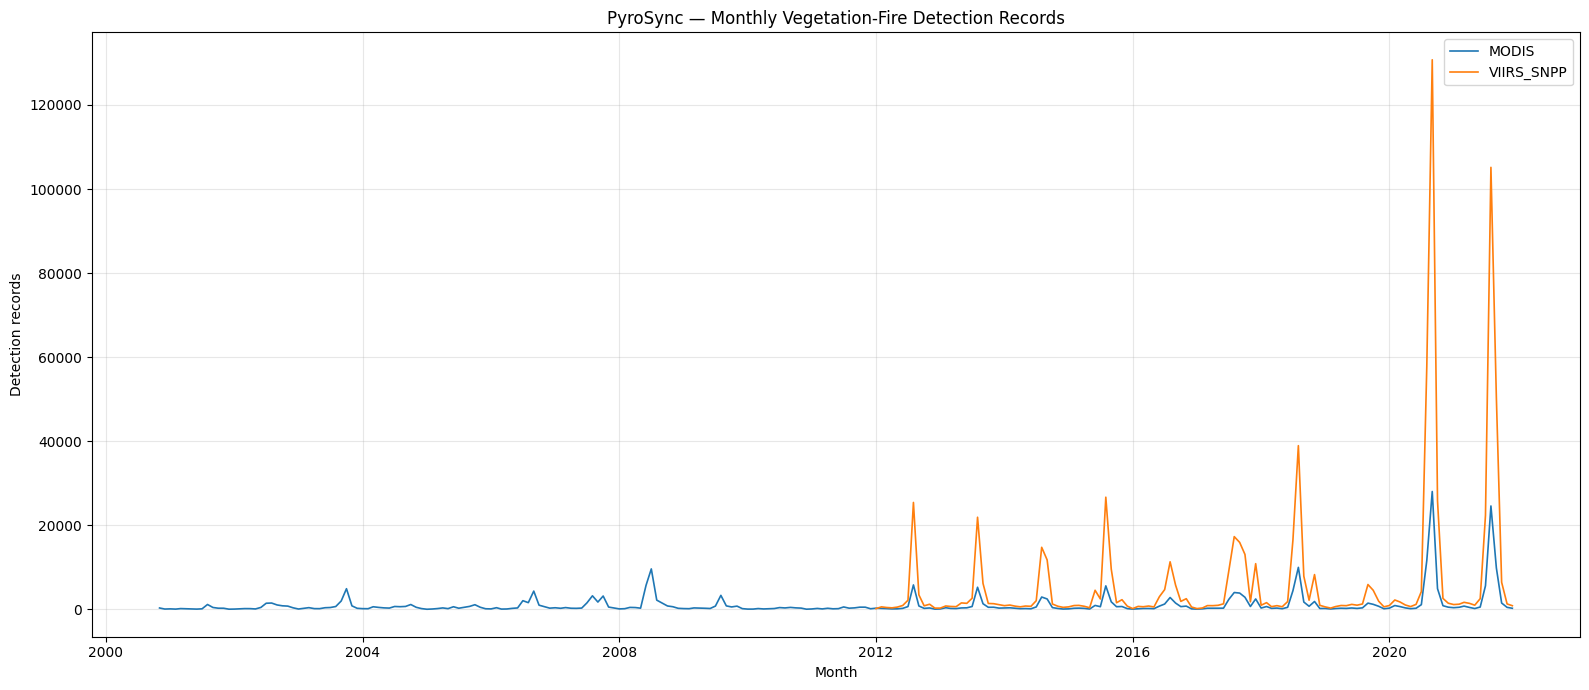

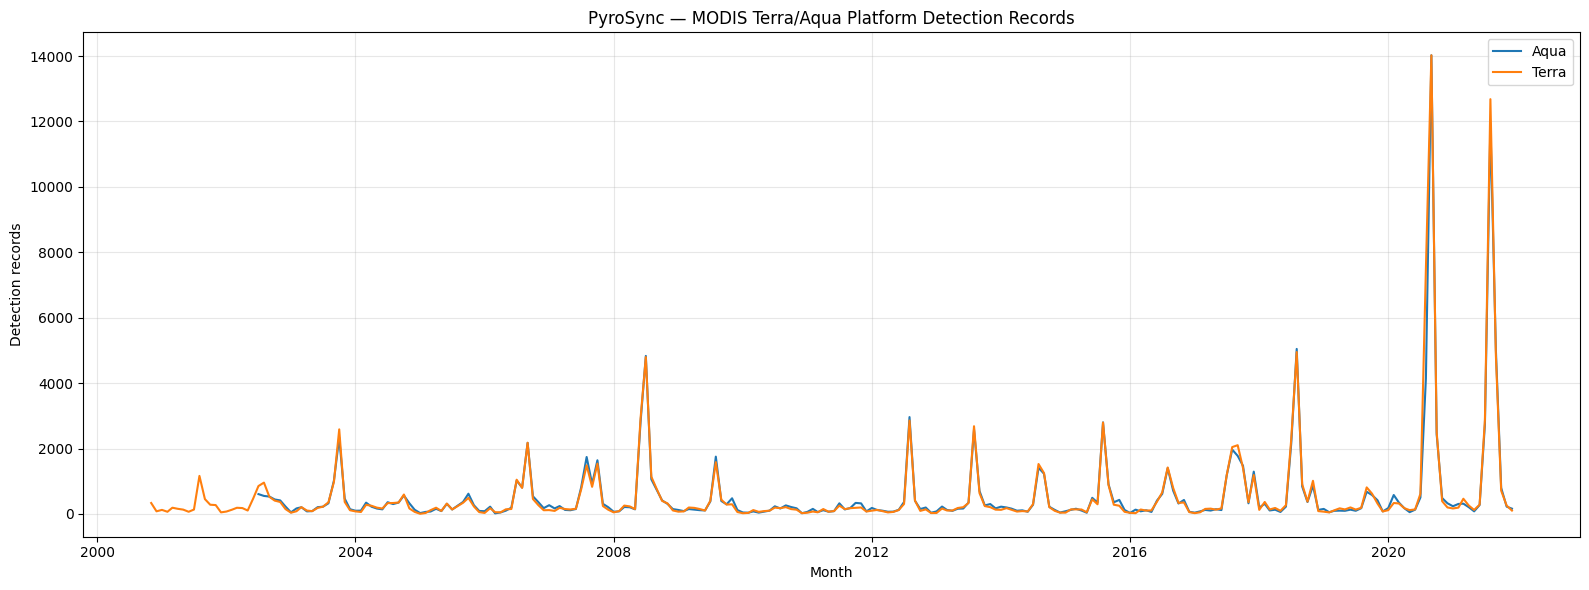

In [13]:
plt.figure(figsize=(16, 7))
for sensor in ["MODIS", "VIIRS_SNPP"]:
    s = monthly_all[monthly_all["sensor"] == sensor]
    plt.plot(s["month"], s["detection_count"], label=sensor, linewidth=1.2)
plt.title("PyroSync — Monthly Vegetation-Fire Detection Records")
plt.xlabel("Month"); plt.ylabel("Detection records")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
plt.savefig(REPORT_DIR / "monthly_detection_trends.png", dpi=200, bbox_inches="tight")
plt.show()

platform_monthly = (modis_vegetation
    .assign(month=modis_vegetation["date"].dt.to_period("M").dt.to_timestamp())
    .groupby(["month", "satellite"]).size().reset_index(name="detection_count"))

plt.figure(figsize=(16, 6))
for platform in sorted(platform_monthly["satellite"].dropna().unique()):
    s = platform_monthly[platform_monthly["satellite"] == platform]
    plt.plot(s["month"], s["detection_count"], label=str(platform))
plt.title("PyroSync — MODIS Terra/Aqua Platform Detection Records")
plt.xlabel("Month"); plt.ylabel("Detection records")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
plt.savefig(REPORT_DIR / "modis_platform_detection_trends.png", dpi=200, bbox_inches="tight")
plt.show()

In [14]:
log_df = pd.DataFrame(cleaning_log)
log_df.to_csv(OUT / "cleaning_log.csv", index=False)
display(log_df)

,sensor,rule,rows_before,rows_removed,rows_remaining
0,MODIS,requested analysis period,286556,0,286556
1,MODIS,valid geographic coordinates,286556,0,286556
2,MODIS,valid acquisition timestamp,286556,0,286556
3,MODIS,remove negative FRP,286556,0,286556
4,MODIS,remove exact duplicates,286556,0,286556
5,VIIRS_SNPP,requested analysis period,855929,0,855929
6,VIIRS_SNPP,valid geographic coordinates,855929,0,855929
7,VIIRS_SNPP,valid acquisition timestamp,855929,0,855929
8,VIIRS_SNPP,remove negative FRP,855929,0,855929
9,VIIRS_SNPP,remove exact duplicates,855929,0,855929


In [15]:
OUTPUT_DATASETS = {
    "modis_clean": modis_ca,
    "viirs_clean": viirs_ca,
    "modis_vegetation": modis_vegetation,
    "viirs_vegetation": viirs_vegetation,
    "monthly_modis": modis_monthly,
    "monthly_viirs": viirs_monthly,
    "monthly_platform": monthly_all,
}

for name, df in OUTPUT_DATASETS.items():
    pq = OUT / f"{name}.parquet"
    df.to_parquet(pq, index=False)
    df.to_csv(OUT / f"{name}.csv", index=False)
    print(f"{name:18} rows={len(df):>9,} | parquet {pq.stat().st_size/(1024**2):.2f} MB")

modis_clean        rows=  286,544 | parquet 4.20 MB
viirs_clean        rows=  855,909 | parquet 18.08 MB
modis_vegetation   rows=  279,986 | parquet 4.06 MB
viirs_vegetation   rows=  797,147 | parquet 16.85 MB
monthly_modis      rows=      254 | parquet 0.01 MB
monthly_viirs      rows=      120 | parquet 0.01 MB
monthly_platform   rows=      374 | parquet 0.02 MB


In [16]:
metadata = {
    "project": PROJECT_NAME,
    "challenge": f"NASA Space Apps Challenge 2026: {CHALLENGE_NAME}",
    "phase": 2,
    "phase_name": "Data Cleaning and Preparation",
    "study_area": {
        "region": STUDY_REGION, "country": COUNTRY, "geographic_crs": SOURCE_CRS,
        "boundary_method": "Census TIGER/Line 2024 California polygon (point-in-polygon, 'within')",
    },
    "data_sources": {
        "MODIS": {"product": "MODIS Collection 6.1", "source_file": MODIS_PATH.name,
                  "platforms": sorted(modis_ca["satellite"].dropna().astype(str).unique().tolist())},
        "VIIRS": {"product": "Suomi-NPP VIIRS Collection 2", "source_file": VIIRS_PATH.name,
                  "platform": "S-NPP", "archive_start": str(VIIRS_ARCHIVE_START.date())},
    },
    "requested_period": {"start": str(START_DATE.date()), "end": str(END_DATE.date())},
    "cleaning_rules": [
        "Standardize field names and data types",
        "Keep records within the analysis period",
        "Remove invalid coordinates and timestamps",
        "Remove negative FRP; retain missing FRP",
        "Remove exact duplicates",
        "Clip to California polygon",
        "Keep all detection types in primary datasets",
        "Create separate type 0 vegetation-fire datasets",
    ],
    "confidence_standardization": {
        "MODIS": {"low": "<30", "nominal": "30-79", "high": ">=80"},
        "VIIRS": {"low": "l", "nominal": "n", "high": "h"},
        "limitation": "Common labels do not imply statistically equivalent confidence.",
    },
    "important_limitations": [
        "Detection records are not unique fire counts.",
        "Detection counts do not measure valid observation coverage.",
        "No detection records do not prove zero fire activity.",
        "MODIS (1 km) and VIIRS (375 m) differ in resolution; brightness is not assumed equivalent.",
        "Missing FRP is retained, not treated as zero.",
        "The archive ends in December 2021.",
    ],
    "row_counts": {k: int(len(v)) for k, v in OUTPUT_DATASETS.items()},
}

with open(OUT / "phase2_metadata.json", "w") as f:
    json.dump(metadata, f, indent=4)
print("Metadata saved.")

Metadata saved.


In [17]:
print("=" * 80)
print("PYROSYNC — PHASE 2 FINAL REPORT")
print("=" * 80)

print("\n1. CONFIGURATION")
print(f"Region: {STUDY_REGION}, {COUNTRY} | CRS: {SOURCE_CRS}")
print(f"Period: {START_DATE.date()} to {END_DATE.date()}")

print("\n2. CLEANING SUMMARY")
print(log_df.to_string(index=False))

print("\n3. FINAL DATASETS")
for name, df in OUTPUT_DATASETS.items():
    print(f"{name:18} {len(df):>9,} rows")

print("\n4. PLATFORMS")
print("MODIS:", modis_ca["satellite"].value_counts().to_dict())
print("VIIRS:", viirs_ca["satellite"].value_counts().to_dict())

print("\n5. CONFIDENCE CLASSES")
print("MODIS:", modis_ca["confidence_class"].value_counts().to_dict())
print("VIIRS:", viirs_ca["confidence_class"].value_counts().to_dict())

print("\n6. LIMITATIONS")
for line in metadata["important_limitations"]:
    print("-", line)

print("\n7. SAVED FILES")
for p in sorted(OUT.iterdir()):
    if p.is_file():
        print(f"{p.name:34} {p.stat().st_size/(1024**2):8.2f} MB")

print("\nPHASE 2 COMPLETED")

PYROSYNC — PHASE 2 FINAL REPORT

1. CONFIGURATION
Region: California, USA | CRS: EPSG:4326
Period: 2000-11-01 to 2021-12-31

2. CLEANING SUMMARY
    sensor                         rule  rows_before  rows_removed  rows_remaining
     MODIS    requested analysis period       286556             0          286556
     MODIS valid geographic coordinates       286556             0          286556
     MODIS  valid acquisition timestamp       286556             0          286556
     MODIS          remove negative FRP       286556             0          286556
     MODIS      remove exact duplicates       286556             0          286556
VIIRS_SNPP    requested analysis period       855929             0          855929
VIIRS_SNPP valid geographic coordinates       855929             0          855929
VIIRS_SNPP  valid acquisition timestamp       855929             0          855929
VIIRS_SNPP          remove negative FRP       855929             0          855929
VIIRS_SNPP      remove ex